# 01 - Exploratory Data Analysis

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Dataset:** PhiUSIIL Phishing URL Dataset (UCI Machine Learning Repository, 2024)

**Goal:** Before we clean the data or train any model, we want to understand it. In this notebook we look at how big the dataset is, check its quality, see how the two classes are balanced, and find which features are most useful for spotting phishing URLs.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/PhiUSIIL_Phishing_URL_Dataset.csv")
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
CORRELATION_THRESHOLD = 0.95

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

Rows: 235,795 | Columns: 56


## 1. Dataset Overview

In [3]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.000,1.000,0.523,0.062,3,1,0,0,0.000,18,0.581,0,0.000,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000,0.000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.000,0.667,0.033,0.050,2,1,0,0,0.000,9,0.391,0,0.000,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.556,55.556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.000,0.867,0.029,0.064,2,2,0,0,0.000,15,0.517,0,0.000,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.667,46.667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.000,1.000,0.523,0.058,3,1,0,0,0.000,13,0.500,0,0.000,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000,0.000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.000,1.000,0.080,0.059,3,1,0,0,0.000,20,0.606,0,0.000,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000,100.000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [5]:
text_cols = df.select_dtypes(include="str").columns.tolist()
print(f"Text columns ({len(text_cols)}): {text_cols}")

Text columns (5): ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']


## 2. Data Quality Check

In [6]:
missing = df.isnull().sum()
print(f"Total missing values: {missing.sum()}")
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

In [7]:
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

Duplicate rows: 0


In [8]:
duplicate_urls = df["URL"].duplicated().sum()
print(f"Duplicate URLs: {duplicate_urls}")

Duplicate URLs: 425


In [9]:
dup_mask = df["URL"].duplicated(keep=False)
dup_df = df[dup_mask]
label_conflicts = dup_df.groupby("URL")["label"].nunique()

print(f"Rows involved in duplication: {dup_mask.sum()}")
print(f"Unique duplicated URLs: {dup_df['URL'].nunique()}")
print(f"URLs with conflicting labels: {(label_conflicts > 1).sum()}")

Rows involved in duplication: 850
Unique duplicated URLs: 425
URLs with conflicting labels: 0


Some URLs may also be repeated in a slightly different form, for example with and without a `/` at the end, or with capital letters. To find these, we make the URLs consistent (remove extra spaces, make all letters lowercase and remove a `/` at the end) and check again.

In [ ]:
url_key = df["URL"].str.strip().str.lower().str.rstrip("/")
key_mask = url_key.duplicated(keep=False)
key_conflicts = df[key_mask].groupby(url_key[key_mask])["label"].nunique()

print(f"Duplicate URLs after making them consistent: {url_key.duplicated().sum()}")
print(f"Extra duplicates found this way: {url_key.duplicated().sum() - duplicate_urls}")
print(f"URLs with conflicting labels: {(key_conflicts > 1).sum()}")

Duplicate URLs after making them consistent: 1590
Extra duplicates found this way: 1165
URLs with conflicting labels: 1


### Findings: Data Quality

- The dataset has 235,795 rows and 56 columns, and there are no missing values.
- Five columns contain text: `FILENAME`, `URL`, `Domain`, `TLD` and `Title`. Models cannot use text directly, so these will need to be removed.
- At first, no duplicate rows were found. This is only because every row has a different `FILENAME`.
- When we checked the `URL` column alone, we found that **425 URLs appear twice** (850 rows). Each pair has the same label, so there is no conflicting data.
- After making the URLs consistent, we found **1,165 more repeated URLs**, mostly the same URL with and without a `/` at the end. One of them (`https://www.education.gouv.fr`) has two different labels.
- We will remove all these duplicates during preprocessing, and remove both copies of the URL with two different labels, because we cannot know which label is right. If we keep them, the same URL could end up in both the training set and the test set, and the model would be tested on data it has already seen.

## 3. Class Distribution

In [10]:
LABEL_NAMES = {0: "Phishing", 1: "Legitimate"}

class_counts = df["label"].map(LABEL_NAMES).value_counts()
class_pct = (class_counts / len(df) * 100).round(2)
pd.DataFrame({"Count": class_counts, "Percentage (%)": class_pct})

,Count,Percentage (%)
label,,
Legitimate,134850,57.190
Phishing,100945,42.810


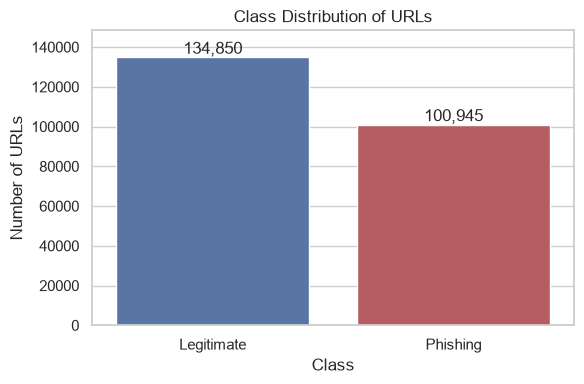

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
class_labels = df["label"].map(LABEL_NAMES)
sns.countplot(x=class_labels, hue=class_labels, order=["Legitimate", "Phishing"], palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")

ax.margins(y=0.1)
ax.set_title("Class Distribution of URLs")
ax.set_xlabel("Class")
ax.set_ylabel("Number of URLs")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "class_distribution.png", dpi=300)
plt.show()

### Findings: Class Distribution

- There are 134,850 legitimate URLs (57.19%) and 100,945 phishing URLs (42.81%).
- In this dataset, the label is **1 for legitimate** and **0 for phishing**.
- A 57:43 split is fairly balanced, so we do not need techniques like SMOTE to create extra samples.
- We will still use a stratified split, so the training and test sets keep the same 57:43 ratio.
- A model that simply guesses "legitimate" every time would already get about 57% accuracy. Because of this, we will not rely on accuracy alone. We will also look at precision, recall and F1-score.

## 4. Feature Correlation with Target

In [12]:
numeric_df = df.drop(columns=text_cols)
target_corr = numeric_df.corr()["label"].drop("label").sort_values(key=abs, ascending=False)
target_corr.head(15)

URLSimilarityIndex       0.860
HasSocialNet             0.784
HasCopyrightInfo         0.743
HasDescription           0.690
IsHTTPS                  0.609
DomainTitleMatchScore    0.585
HasSubmitButton          0.579
IsResponsive             0.549
URLTitleMatchScore       0.539
SpacialCharRatioInURL   -0.534
HasHiddenFields          0.508
HasFavicon               0.494
URLCharProb              0.470
CharContinuationRate     0.468
HasTitle                 0.460
Name: label, dtype: float64

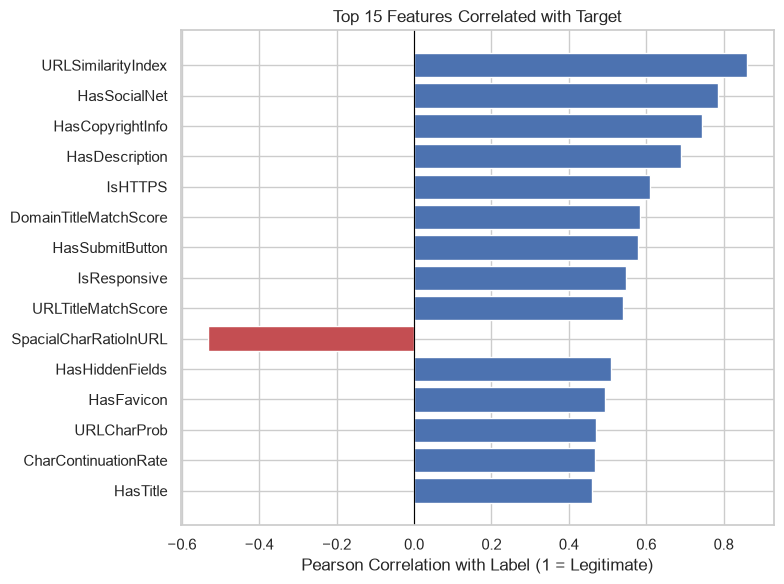

In [13]:
top_corr = target_corr.head(15)
colors = ["#4C72B0" if value > 0 else "#C44E52" for value in top_corr]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_corr.index[::-1], top_corr.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top 15 Features Correlated with Target")
ax.set_xlabel("Pearson Correlation with Label (1 = Legitimate)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "feature_correlation.png", dpi=300)
plt.show()

### Findings: Feature Correlation

- `URLSimilarityIndex` has the strongest link to the label (0.86). On its own, it is the most useful feature in the dataset.
- Features that describe the web page, such as `HasSocialNet` (0.78), `HasCopyrightInfo` (0.74) and `HasDescription` (0.69), are much more common on legitimate websites.
- `IsHTTPS` (0.61) shows that legitimate websites are more likely to use HTTPS.
- `SpacialCharRatioInURL` (-0.53) is the strongest negative feature. URLs with more special characters are more likely to be phishing.
- Some features are very strongly linked to the label, so we expect the models to reach very high accuracy. We will keep this in mind when we discuss the results.
- Most bars are positive only because 1 means legitimate. If a page does **not** have these features, it is more likely to be phishing.

## 5. Descriptive Statistics

In [14]:
numeric_cols = df.select_dtypes(include="number").columns.drop("label")

binary_cols = [col for col in numeric_cols if df[col].nunique() == 2]
continuous_cols = [col for col in numeric_cols if df[col].nunique() > 2]
constant_cols = [col for col in numeric_cols if df[col].nunique() <= 1]

print(f"Numeric features: {len(numeric_cols)}")
print(f"Binary features (0/1): {len(binary_cols)}")
print(f"Continuous features: {len(continuous_cols)}")
print(f"Constant features: {len(constant_cols)} {constant_cols}")

Numeric features: 50
Binary features (0/1): 19
Continuous features: 31
Constant features: 0 []


In [15]:
desc = df[continuous_cols].describe().T
desc["range"] = desc["max"] - desc["min"]
desc.sort_values("range", ascending=False).round(3)

,count,mean,std,min,25%,50%,75%,max,range
LargestLineLength,"235,795.000","12,789.533","152,201.099",22.000,200.000,"1,090.000","8,047.000","13,975,732.000","13,975,710.000"
LineOfCode,"235,795.000","1,141.900","3,419.951",2.000,18.000,429.000,"1,277.000","442,666.000","442,664.000"
NoOfCSS,"235,795.000",6.333,74.866,0.000,0.000,2.000,8.000,"35,820.000","35,820.000"
NoOfExternalRef,"235,795.000",49.263,161.027,0.000,1.000,10.000,57.000,"27,516.000","27,516.000"
NoOfSelfRef,"235,795.000",65.071,176.688,0.000,0.000,12.000,88.000,"27,397.000","27,397.000"
NoOfImage,"235,795.000",26.076,79.412,0.000,0.000,8.000,29.000,"8,956.000","8,956.000"
NoOfJS,"235,795.000",10.522,22.312,0.000,0.000,6.000,15.000,"6,957.000","6,957.000"
URLLength,"235,795.000",34.573,41.314,13.000,23.000,27.000,34.000,"6,097.000","6,084.000"
NoOfLettersInURL,"235,795.000",19.429,29.090,0.000,10.000,14.000,20.000,"5,191.000","5,191.000"
NoOfEmptyRef,"235,795.000",2.378,17.641,0.000,0.000,0.000,1.000,"4,887.000","4,887.000"


In [16]:
skewness = df[continuous_cols].skew().sort_values(ascending=False)
highly_skewed = skewness[skewness.abs() > 1]
print(f"Highly skewed features (|skew| > 1): {len(highly_skewed)} of {len(continuous_cols)}")
highly_skewed.round(2)

Highly skewed features (|skew| > 1): 26 of 31


NoOfCSS                      464.400
NoOfObfuscatedChar           204.680
NoOfJS                       140.440
NoOfEqualsInURL              114.990
NoOfEmptyRef                 106.830
NoOfAmpersandInURL           106.720
NoOfiFrame                    97.680
NoOfDegitsInURL               94.880
NoOfPopup                     84.950
NoOfExternalRef               65.900
NoOfSelfRef                   60.380
NoOfLettersInURL              58.400
URLLength                     53.320
LineOfCode                    53.070
LargestLineLength             48.180
NoOfOtherSpecialCharsInURL    47.430
ObfuscationRatio              40.120
NoOfImage                     28.230
NoOfQMarkInURL                 8.160
DegitRatioInURL                3.240
DomainLength                   2.510
NoOfSubDomain                  1.810
TLDLength                      1.660
SpacialCharRatioInURL          1.180
URLCharProb                   -1.060
CharContinuationRate          -1.130
dtype: float64

### Findings: Descriptive Statistics

- There are 50 numeric features: 19 are binary (0 or 1) and 31 are continuous. No feature has the same value in every row.
- The features have very different ranges. For example, `TLDLegitimateProb` goes from 0 to 0.52, but `LargestLineLength` goes from 22 to almost 14 million. Models like Logistic Regression, KNN and SVM are affected by this, so these features must be scaled.
- 26 of the 31 continuous features are highly skewed (skew above 1). The worst cases are `NoOfCSS` (464.4), `NoOfObfuscatedChar` (204.7) and `NoOfJS` (140.4).
- In many count features, most values are 0 or small, but a few are extremely large. For example, `LargestLineLength` has a mean of 12,790 but a median of only 1,090.
- We will **not** remove these large values. They are not mistakes. Real web pages can be very different in size, and this difference may help to tell phishing and legitimate pages apart.
- For models that are sensitive to scale, we will apply a log transformation (`log1p`) to reduce the effect of these large values. Tree-based models do not need this, so they will use the original values.

## 6. Feature Distributions by Class

In [17]:
top_continuous = target_corr[target_corr.index.isin(continuous_cols)].head(6).index.tolist()
top_continuous

['URLSimilarityIndex',
 'DomainTitleMatchScore',
 'URLTitleMatchScore',
 'SpacialCharRatioInURL',
 'URLCharProb',
 'CharContinuationRate']

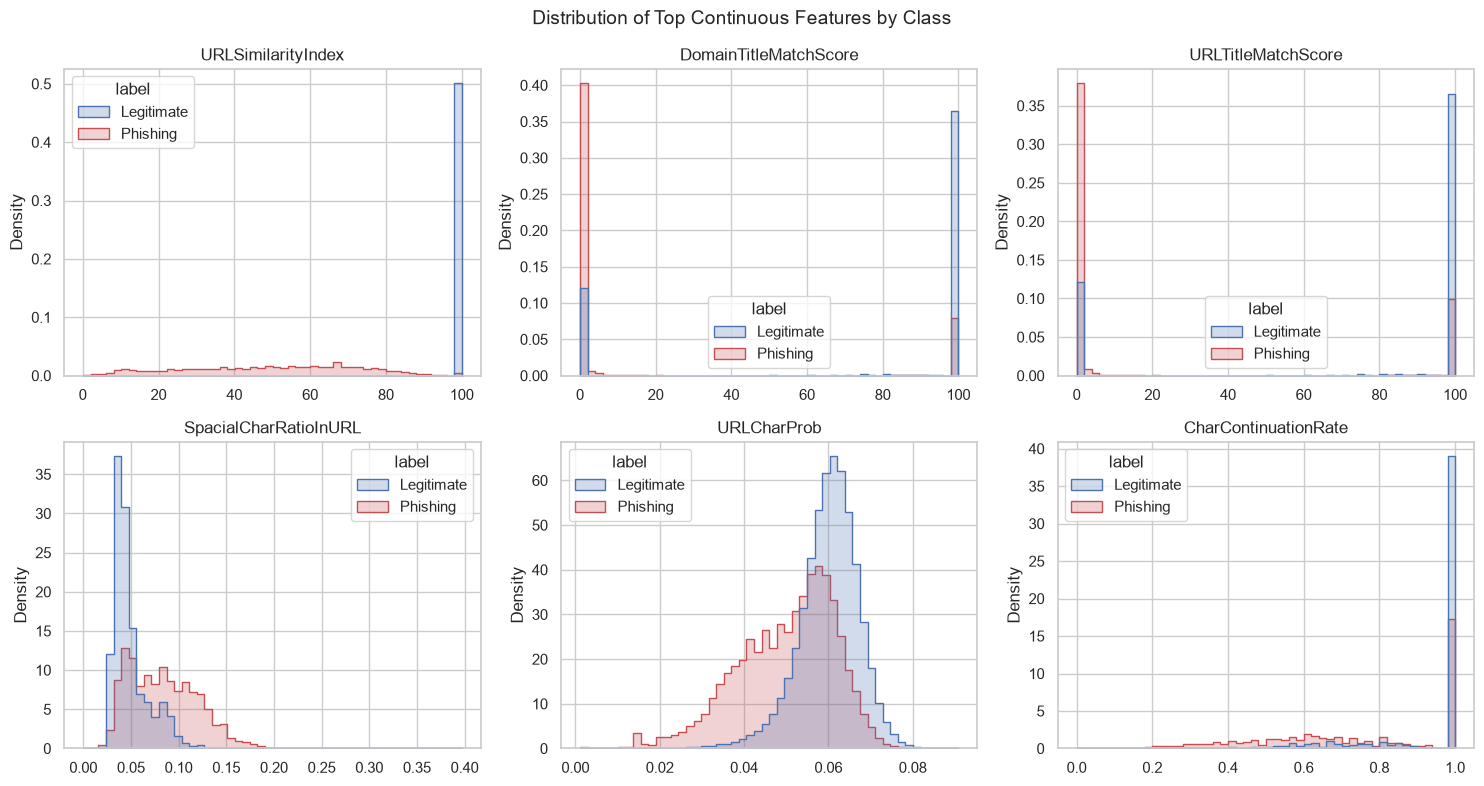

In [18]:
class_labels = df["label"].map(LABEL_NAMES)
class_palette = {"Legitimate": "#4C72B0", "Phishing": "#C44E52"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, top_continuous):
    sns.histplot(x=df[col], hue=class_labels, bins=50, stat="density", common_norm=False, element="step", palette=class_palette, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")

fig.suptitle("Distribution of Top Continuous Features by Class", fontsize=14)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "continuous_feature_distributions.png", dpi=300)
plt.show()

In [19]:
top_binary = target_corr[target_corr.index.isin(binary_cols)].head(8).index.tolist()
binary_rates = df.groupby(class_labels)[top_binary].mean().T * 100
binary_rates.round(1)

label,Legitimate,Phishing
HasSocialNet,79.500,0.500
HasCopyrightInfo,80.800,5.700
HasDescription,73.700,4.400
IsHTTPS,100.000,49.200
HasSubmitButton,66.100,8.500
IsResponsive,85.400,31.700
HasHiddenFields,59.100,9.300
HasFavicon,56.700,8.800


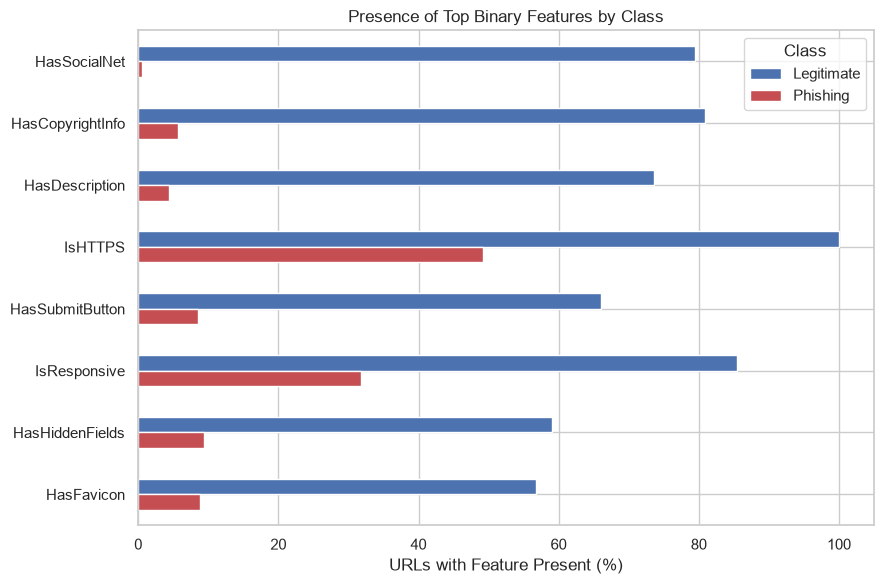

In [20]:
ax = binary_rates.plot(kind="barh", figsize=(9, 6), color=[class_palette["Legitimate"], class_palette["Phishing"]])
ax.set_title("Presence of Top Binary Features by Class")
ax.set_xlabel("URLs with Feature Present (%)")
ax.get_legend().set_title("Class")
ax.set_ylabel("")
ax.legend(title="Class")
ax.invert_yaxis()

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "binary_feature_presence.png", dpi=300)
plt.show()

### Findings: Feature Distributions by Class

- `URLSimilarityIndex` separates the two classes almost perfectly. Nearly all legitimate URLs have a value of 100, while phishing URLs are spread from 0 to 100.
- `DomainTitleMatchScore` and `URLTitleMatchScore` are mostly either 0 or 100. Phishing pages usually score 0 and legitimate pages usually score 100. This means the title of a phishing page rarely matches its domain name.
- Phishing URLs usually have more special characters and a lower `URLCharProb`. However, the two classes overlap here, so these features are helpful but not perfect.
- `HasSocialNet` is the strongest binary feature. It appears on 79.5% of legitimate pages but on only 0.5% of phishing pages.
- Every legitimate URL uses HTTPS (100%), but 49.2% of phishing URLs also use HTTPS. So a padlock in the browser does not prove that a website is safe.
- Features about the page content (social media links, copyright text, page description) are very good at telling the classes apart. This explains the strong correlations we saw in Section 4.

## 7. Multicollinearity Analysis

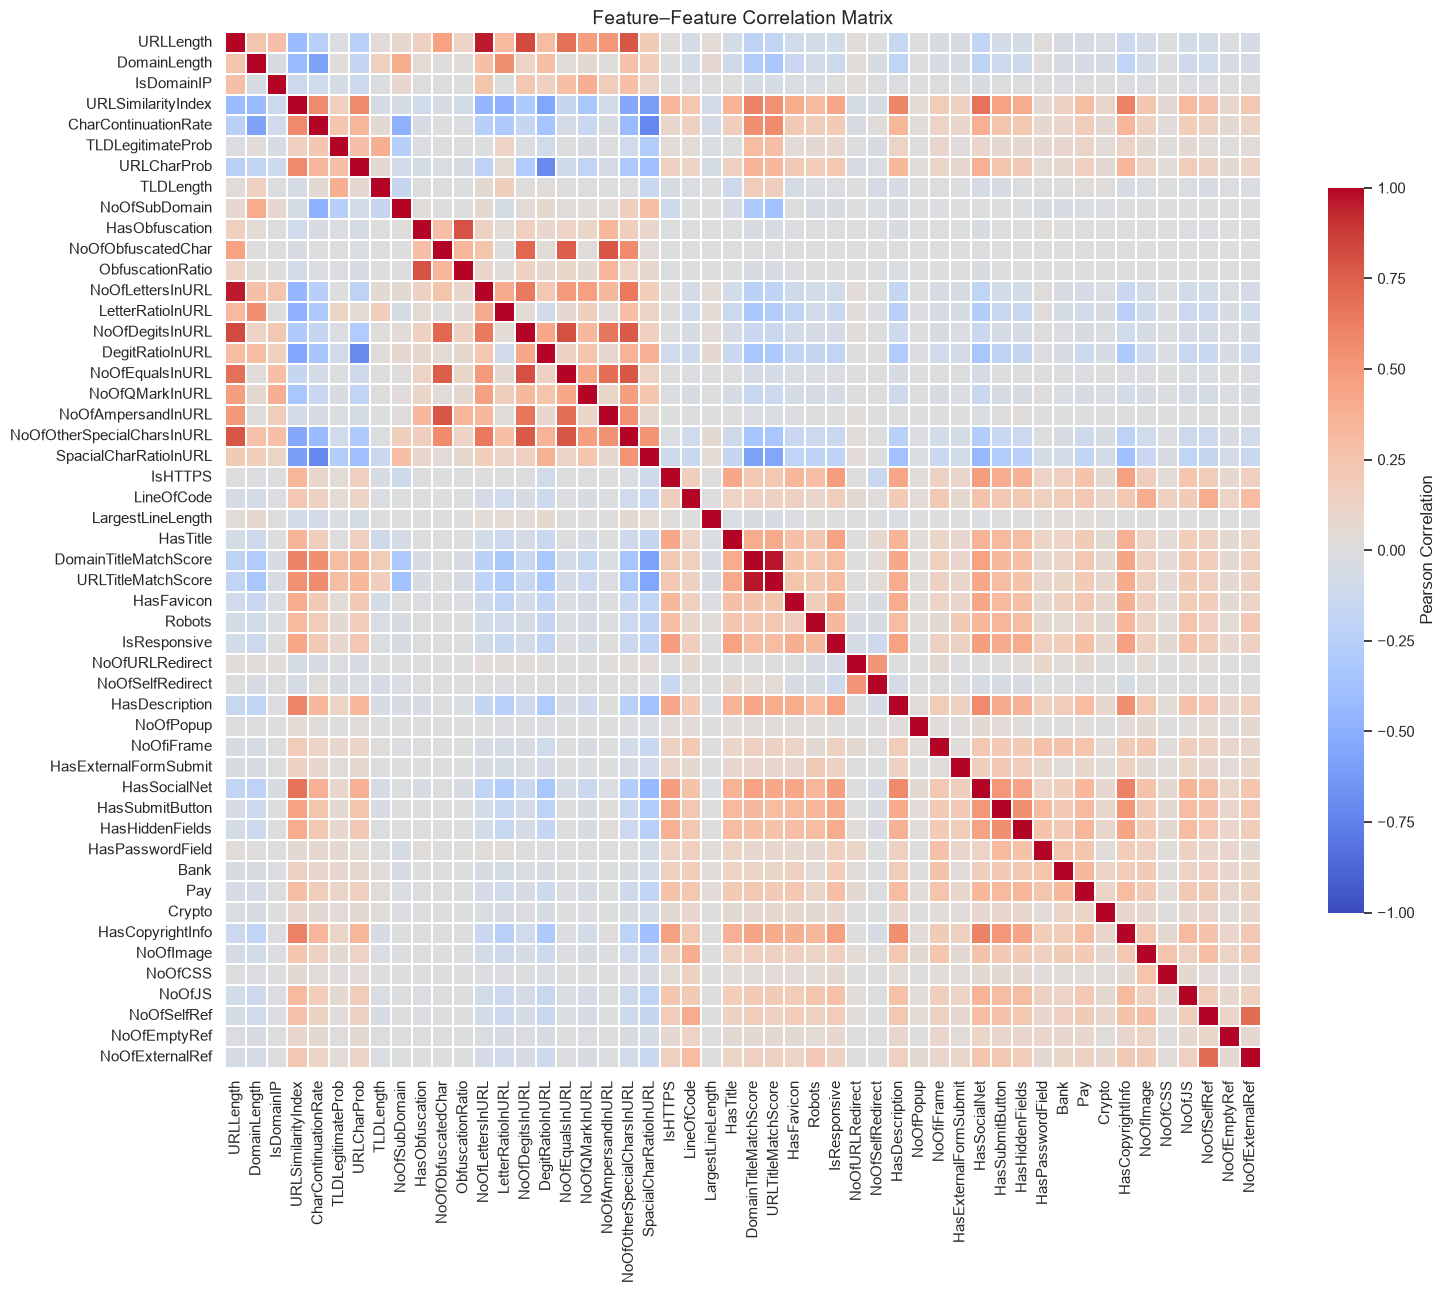

In [21]:
corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.3, cbar_kws={"shrink": 0.7, "label": "Pearson Correlation"}, ax=ax)
ax.set_title("Feature–Feature Correlation Matrix", fontsize=14)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "correlation_heatmap.png", dpi=300)
plt.show()

In [22]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
pairs = upper.stack().dropna()

high_corr_pairs = pairs[pairs.abs() > CORRELATION_THRESHOLD].sort_values(key=abs, ascending=False)
high_corr_pairs.index.names = ["Feature 1", "Feature 2"]

print(f"Feature pairs with |correlation| > {CORRELATION_THRESHOLD}: {len(high_corr_pairs)}")
high_corr_pairs.rename("Correlation").round(3).reset_index()

Feature pairs with |correlation| > 0.95: 2


,Feature 1,Feature 2,Correlation
0,DomainTitleMatchScore,URLTitleMatchScore,0.961
1,URLLength,NoOfLettersInURL,0.956


In [23]:
features_to_drop = [
    feature_2 if abs(target_corr[feature_1]) >= abs(target_corr[feature_2]) else feature_1
    for feature_1, feature_2 in high_corr_pairs.index
]

pd.DataFrame({
    "Pair": [f"{f1} ↔ {f2}" for f1, f2 in high_corr_pairs.index],
    "Feature to Drop": features_to_drop,
})

,Pair,Feature to Drop
0,DomainTitleMatchScore ↔ URLTitleMatchScore,URLTitleMatchScore
1,URLLength ↔ NoOfLettersInURL,URLLength


### Findings: Multicollinearity

- Only two pairs of features have a correlation above 0.95:
  - `DomainTitleMatchScore` and `URLTitleMatchScore` (0.961). Both measure how well the page title matches the domain or URL.
  - `URLLength` and `NoOfLettersInURL` (0.956). A longer URL naturally has more letters.
- In each pair, the two features give almost the same information. We will keep the one that is more strongly linked to the label and remove the other. This means **`URLTitleMatchScore`** and **`URLLength`** will be removed during preprocessing.
- Some other groups of features are also related, such as the URL character counts, the obfuscation features (`HasObfuscation`, `NoOfObfuscatedChar`, `ObfuscationRatio`) and the link counts (`NoOfSelfRef`, `NoOfExternalRef`). These are below 0.95, so we keep them because each one may still add some useful information.
- Removing repeated features should help models such as Logistic Regression and Naive Bayes, which do not work well when features carry the same information.

## 8. Top-Level Domain (TLD) Analysis

In [24]:
tld_stats = df.assign(is_phishing=df["label"].eq(0)).groupby("TLD").agg(
    total=("is_phishing", "size"),
    phishing_rate=("is_phishing", "mean"),
)
tld_stats["phishing_rate"] *= 100
overall_phishing_rate = df["label"].eq(0).mean() * 100

top_tlds = tld_stats.sort_values("total", ascending=False).head(15)

print(f"Unique TLDs: {df['TLD'].nunique()}")
print(f"Overall phishing rate: {overall_phishing_rate:.1f}%")
top_tlds.round(1)

Unique TLDs: 695
Overall phishing rate: 42.8%


,total,phishing_rate
TLD,,
com,112554,38.900
org,18793,12.100
net,7097,43.700
app,6508,97.800
uk,6395,5.000
co,5422,91.600
io,4201,89.700
de,3996,17.200
ru,3875,77.000


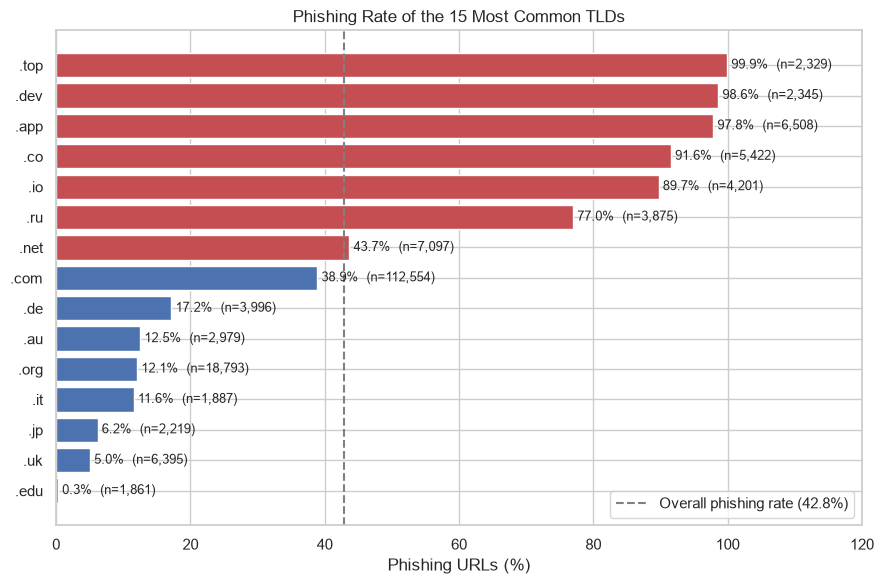

In [25]:
plot_data = top_tlds.sort_values("phishing_rate")
colors = [class_palette["Phishing"] if rate > overall_phishing_rate else class_palette["Legitimate"] for rate in plot_data["phishing_rate"]]

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh([f".{tld}" for tld in plot_data.index], plot_data["phishing_rate"], color=colors)
ax.bar_label(bars, labels=[f"{rate:.1f}%  (n={n:,})" for rate, n in zip(plot_data["phishing_rate"], plot_data["total"])], padding=3, fontsize=9)
ax.axvline(overall_phishing_rate, linestyle="--", color="gray", label=f"Overall phishing rate ({overall_phishing_rate:.1f}%)")

ax.set_xlim(0, 120)
ax.set_title("Phishing Rate of the 15 Most Common TLDs")
ax.set_xlabel("Phishing URLs (%)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "tld_phishing_rate.png", dpi=300)
plt.show()

### Findings: TLD Analysis

- There are 695 different TLDs in the dataset. Overall, 42.8% of URLs are phishing.
- Some TLDs are used almost only for phishing: `.top` (99.9%), `.dev` (98.6%), `.app` (97.8%), `.co` (91.6%), `.io` (89.7%) and `.ru` (77.0%). These domains are often cheap or easy to register, which makes them popular with attackers.
- Some TLDs are very safe, such as `.edu` (0.3%), `.uk` (5.0%) and `.jp` (6.2%). For example, only universities can register `.edu` domains.
- `.com` has a phishing rate of 38.9%, which is a little below the average. But because `.com` is so popular, it still has the largest number of phishing URLs.
- With 695 categories, turning `TLD` into separate columns (one-hot encoding) would add hundreds of new columns. This is not practical. The dataset already has `TLDLegitimateProb`, which stores the TLD information as a single number, so we will remove the `TLD` text column during preprocessing.

## 9. EDA Summary and Preprocessing Plan

### Key Findings

| Area | What We Found |
|---|---|
| **Dataset size** | 235,795 URLs and 56 columns (50 numeric features, 5 text columns and 1 label) |
| **Data quality** | No missing values. 1,590 URLs appear twice (425 exactly, 1,165 in a slightly different form). Only 1 of them has two different labels |
| **Class balance** | 57.19% legitimate and 42.81% phishing, which is fairly balanced |
| **Most useful features** | `URLSimilarityIndex` (0.86), `HasSocialNet` (0.78), `HasCopyrightInfo` (0.74), `HasDescription` (0.69) |
| **Feature ranges** | Very different, from 0–0.52 up to 0–14 million |
| **Skewness** | 26 of the 31 continuous features are highly skewed |
| **Repeated features** | 2 pairs of features carry almost the same information (correlation above 0.95) |
| **TLD** | 695 different TLDs. The phishing rate goes from 0.3% (`.edu`) to 99.9% (`.top`) |

**Overall:** Features about the page content and URL similarity are very good at separating phishing from legitimate URLs, so we expect high scores from the models. Because of this, we will compare the models using several metrics, not just accuracy.

### Preprocessing Plan

Based on what we found in the EDA, we will do these steps in `02_preprocessing.ipynb`:

| Step | Action | Why We Do It |
|---|---|---|
| 1 | Check that the data is valid: no negative counts, and binary columns only contain 0 and 1 | To make sure there are no wrong values before training (Section 5) |
| 2 | Make the URLs consistent, remove the 1,590 duplicate URLs and keep the first copy. Remove both copies of the 1 URL with two different labels | The same URL must not appear in both the training set and the test set (Section 2) |
| 3 | Create new features from the URL, the page title and the existing columns (feature engineering) | New features can give the models extra useful information. URL-only features also let us test on a second dataset and use the model in the DetectIt app |
| 4 | Remove the 5 text columns: `FILENAME`, `URL`, `Domain`, `TLD`, `Title` | Models need numbers, not text. The TLD information is already in `TLDLegitimateProb` (Sections 1 and 8) |
| 5 | Remove 2 repeated features: `URLTitleMatchScore` and `URLLength` | Each one gives almost the same information as another feature (Section 7) |
| 6 | Change the label so that 1 = Phishing and 0 = Legitimate | Phishing is what we want to detect, so it should be the positive class (Section 4) |
| 7 | Split the data into 80% training and 20% testing, using a stratified split with `random_state = 42` | Both sets keep the same 57:43 ratio, and everyone in the team gets the same split (Section 3) |
| 8 | Check the split: the class ratio is the same in both sets, and no URL is in both | To show that there is no data leakage |
| 9 | Save `train.csv`, `test.csv` and the list of feature names | So every team member trains their models on exactly the same data |

**Steps we will do later, during model training:**

| Step | Action | Why We Do It |
|---|---|---|
| 10 | Apply a log transform (`log1p`) and scaling for LR, KNN, SVM and Naive Bayes, inside a `Pipeline` | The features have very different ranges and are highly skewed (Section 5). Fitting only on the training data prevents data leakage |
| 11 | Use 5-fold stratified cross-validation on the training set | This gives a more reliable score than a single split. The test set is used only once, at the very end |
| 12 | Train the models with and without `URLSimilarityIndex` | This feature separates the classes almost perfectly (Section 6), so we want to check that the models still work well without it |
| 13 | Use a second dataset, the [Web Page Phishing Detection Dataset](https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset) (11,430 URLs, collected in 2020). Split it 80/20, train URL-feature models on this dataset's 80% together with our training set, and test on each dataset's 20% separately | A high score on our own test set does not prove the model works on new data. Testing on URLs collected by different people at a different time shows how well the model works in the real world, and adding some of these URLs to training helps the model learn from more types of URLs |

**Steps we do not need:**
- **Filling missing values:** there are no missing values.
- **Resampling (e.g. SMOTE):** the classes are fairly balanced.
- **Removing outliers:** the very large values are real properties of web pages, not errors.

**Expected result:** 234,204 URLs with the 48 remaining original features, the new engineered features, and 1 label.